# Revenue Drop Diagnosis: From Alert to Root Cause

**Author:** Yelyzaveta Zakharova, Product Analyst
**Data:** fully simulated data of a fictional subscription dating app ("Driftly"). No real company data is used.

**The alert.** At the end of September 2025, daily subscription revenue was ~20% below August levels. Three things happened in the same two weeks:
iOS app 5.12 (10 Sep), Android app 5.12 staged rollout (15 Sep), and the Meta Ads campaign paused (20 Sep).
The question: is the drop real, what caused it, and how much is it costing?

**Data.** `daily_segments.csv`: daily aggregates by platform × app version × OS version × user type × country group,
with the paywall funnel (paywall views → plan selected → purchase attempts → purchases) and revenue.
`installs_by_channel.csv`: daily installs by channel and platform.

**Approach.** Confirm the anomaly → decompose revenue → drill down → find the broken step → isolate the cause → size the loss.

In [1]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

df = pd.read_csv("data/daily_segments.csv", parse_dates=["date"], dtype={"app_version": str})
inst = pd.read_csv("data/installs_by_channel.csv", parse_dates=["date"])
EV = {"iOS 5.12 release": "2025-09-10", "Android 5.12 rollout": "2025-09-15", "Meta Ads paused": "2025-09-20"}
EV = {k: pd.Timestamp(v) for k, v in EV.items()}
day = df.groupby("date")[["dau", "paywall_views", "plan_selected", "purchase_attempts", "purchases", "revenue_usd"]].sum()
day.tail()

,dau,paywall_views,plan_selected,purchase_attempts,purchases,revenue_usd
date,,,,,,
2025-09-26,256740,24529,6971,4606,3551,85604.08
2025-09-27,268210,25305,7110,4691,3693,89460.59
2025-09-28,249923,23910,6665,4363,3407,81223.93
2025-09-29,231944,22478,6246,4067,3122,75012.93
2025-09-30,227529,22029,6286,4110,3231,76924.51


## 1. Is the drop real?
Baseline model fitted on 1 Jul – 9 Sep, before any of the three events: log revenue ~ linear trend + day of week.
Days outside the 95% prediction interval are anomalies.

In [2]:
d = day.reset_index()
d["t"] = (d.date - d.date.min()).dt.days; d["dow"] = d.date.dt.dayofweek.astype(str); d["lr"] = np.log(d.revenue_usd)
train = d[d.date < EV["iOS 5.12 release"]]
m = smf.ols("lr ~ t + C(dow)", data=train).fit()
pr = m.get_prediction(d).summary_frame(alpha=0.05)
d["expected"] = np.exp(pr["mean"]); d["lo"] = np.exp(pr["obs_ci_lower"]); d["hi"] = np.exp(pr["obs_ci_upper"])
d["gap"] = d.revenue_usd / d.expected - 1
post = d[d.date >= EV["iOS 5.12 release"]]
onset = post[post.revenue_usd < post.lo].date.min()
print(f"Model R² on training window: {m.rsquared:.2f}")
print(f"First day below the 95% band: {onset.date()}")
print(post.set_index("date")[["revenue_usd", "expected", "gap"]].round(3).to_string())

Model R² on training window: 0.87
First day below the 95% band: 2025-09-20
            revenue_usd    expected    gap
date                                      
2025-09-10     91942.48   90931.159  0.011
2025-09-11     95218.75   93942.873  0.014
2025-09-12    102809.42  100385.030  0.024
2025-09-13    106416.29  104615.338  0.017
2025-09-14     96936.32   98621.431 -0.017
2025-09-15     94275.80   92755.568  0.016
2025-09-16     88076.23   91094.855 -0.033
2025-09-17     89812.84   91106.475 -0.014
2025-09-18     90725.93   94123.995 -0.036
2025-09-19     97026.02  100578.573 -0.035
2025-09-20     97057.54  104817.037 -0.074
2025-09-21     92447.92   98811.574 -0.064
2025-09-22     79921.86   92934.401 -0.140
2025-09-23     74986.67   91270.486 -0.178
2025-09-24     79023.53   91282.129 -0.134
2025-09-25     77562.48   94305.467 -0.178
2025-09-26     85604.08  100772.489 -0.151
2025-09-27     89460.59  105019.125 -0.148
2025-09-28     81223.93   99002.083 -0.180
2025-09-29     75012.9

Revenue stays inside the band for ten days after the iOS release, so iOS 5.12 is ruled out early.
It leaves the band on 20 Sep, which is both five days into the Android rollout and the day Meta Ads was paused.
The timing alone can't separate the two candidates, so the next steps have to.

## 2. Decompose revenue
Revenue = DAU × conversion (purchases / DAU) × ARPPU. Compare full weeks: baseline 1–14 Sep vs incident week 22–28 Sep.
The log of each ratio gives each driver's share of the change.

In [3]:
def window(a, b):
    w = day.loc[a:b]
    return pd.Series({"revenue": w.revenue_usd.mean(), "dau": w.dau.mean(),
                      "conv": w.purchases.sum() / w.dau.sum(), "arppu": w.revenue_usd.sum() / w.purchases.sum()})
B, I = window("2025-09-01", "2025-09-14"), window("2025-09-22", "2025-09-28")
dec = pd.DataFrame({"baseline": B, "incident": I}); dec["change"] = dec.incident / dec.baseline - 1
display(dec.round(4))
tot = np.log(I.revenue / B.revenue)
share = {k: np.log(I[k] / B[k]) / tot for k in ["dau", "conv", "arppu"]}
print({k: f"{v:.0%}" for k, v in share.items()}, f"of a {I.revenue/B.revenue-1:+.1%} change")

,baseline,incident,change
revenue,96517.0729,81111.8771,-0.1596
dau,245574.0000,243963.5714,-0.0066
conv,0.0164,0.0138,-0.1575
arppu,23.9255,24.0240,0.0041


{'dau': '4%', 'conv': '99%', 'arppu': '-2%'} of a -16.0% change


Almost the whole drop is conversion. DAU barely moved, because new users are a small share of DAU.
But new users convert about 4x better than existing ones, so losing Meta's new users also shows up as lower conversion.
The drill-down has to separate the two.

## 3. Drill down: where did conversion fall?
For each segment: purchases expected at its **baseline conversion and today's DAU**, against actual purchases.
This removes the DAU effect and shows where conversion itself broke.

In [4]:
base = df[(df.date >= "2025-09-01") & (df.date <= "2025-09-14")]
inc = df[(df.date >= "2025-09-22") & (df.date <= "2025-09-28")]

def drill(dim, b=base, i=inc):
    bb = b.groupby(dim)[["dau", "purchases"]].sum(); ii = i.groupby(dim)[["dau", "purchases"]].sum()
    out = pd.DataFrame({"conv_base": bb.purchases / bb.dau, "conv_now": ii.purchases / ii.dau})
    out["conv_change"] = out.conv_now / out.conv_base - 1
    out["missing_purchases_per_day"] = (out.conv_base * ii.dau - ii.purchases) / 7
    out["share_of_gap"] = out.missing_purchases_per_day / out.missing_purchases_per_day.sum()
    return out.round(4)

for dim in ["platform", "user_type", "country_group"]:
    display(drill(dim))

,conv_base,conv_now,conv_change,missing_purchases_per_day,share_of_gap
platform,,,,,
android,0.0157,0.0116,-0.2619,549.3658,0.8702
ios,0.0173,0.0165,-0.0429,81.9517,0.1298


,conv_base,conv_now,conv_change,missing_purchases_per_day,share_of_gap
user_type,,,,,
existing,0.0134,0.0117,-0.1311,406.7819,0.8492
new,0.0593,0.0536,-0.0960,72.2382,0.1508


,conv_base,conv_now,conv_change,missing_purchases_per_day,share_of_gap
country_group,,,,,
Rest of world,0.0165,0.0137,-0.1685,169.5179,0.2685
Tier-1 other,0.0164,0.0139,-0.1499,179.8563,0.2849
US,0.0164,0.0138,-0.1565,281.9535,0.4466


Android carries 87% of the conversion gap. The rest, on iOS, comes from fewer new users after the Meta pause. Next: version and OS inside Android.

In [5]:
# version split: compare 5.12 users with 5.11 users on the same days (avoids mixing old and new periods)
inc_a = inc[inc.platform == "android"]; base_a = base[base.platform == "android"]
cells = []
for osb in sorted(df[df.platform == "android"].os_version.unique()):
    b = base_a[base_a.os_version == osb]; bconv = b.purchases.sum() / b.dau.sum()
    for ver in ["5.11", "5.12"]:
        x = inc_a[(inc_a.os_version == osb) & (inc_a.app_version == ver)]
        cells.append(dict(os_version=osb, app_version=ver, dau_per_day=x.dau.sum() / 7,
                          conv=x.purchases.sum() / x.dau.sum(), conv_vs_baseline=x.purchases.sum() / x.dau.sum() / bconv - 1))
cells = pd.DataFrame(cells)
display(cells.round(4))

,os_version,app_version,dau_per_day,conv,conv_vs_baseline
0,Android 13 and older,5.11,971.2857,0.0126,-0.1920
1,Android 13 and older,5.12,59514.7143,0.0153,-0.0245
2,Android 14+,5.11,1168.8571,0.0159,0.0064
3,Android 14+,5.12,71699.1429,0.0085,-0.4626


Only one cell is broken: **Android 14+ on app 5.12** (−46%). The same app version on older Android converts normally, and Android 14+ users still on 5.11 convert normally.
(The −19% on Android 13 and older on 5.11 is noise: those are ~1,000 stragglers who haven't updated.)
That rules out the app version alone, the OS alone, and anything seasonal or market-wide.

## 4. Which funnel step breaks?

In [6]:
def funnel(x):
    s = x[["dau", "paywall_views", "plan_selected", "purchase_attempts", "purchases"]].sum()
    return pd.Series({"Paywall view rate": s.paywall_views / s.dau, "Plan selection rate": s.plan_selected / s.paywall_views,
                      "Attempts per selection": s.purchase_attempts / s.plan_selected,
                      "Payment success rate": s.purchases / s.purchase_attempts})
A = inc[(inc.platform == "android") & (inc.os_version == "Android 14+")]
fun = pd.DataFrame({
    "Android 14+ on 5.12 (affected)": funnel(A[A.app_version == "5.12"]),
    "Android 14+ on 5.11": funnel(A[A.app_version == "5.11"]),
    "Android 13 and older on 5.12": funnel(inc[(inc.platform == "android") & (inc.os_version != "Android 14+") & (inc.app_version == "5.12")]),
    "iOS (all)": funnel(inc[inc.platform == "ios"]),
})
fun.round(3)

,Android 14+ on 5.12 (affected),Android 14+ on 5.11,Android 13 and older on 5.12,iOS (all)
Paywall view rate,0.095,0.099,0.094,0.098
Plan selection rate,0.280,0.284,0.281,0.283
Attempts per selection,0.734,0.593,0.624,0.624
Payment success rate,0.436,0.949,0.930,0.951


Users reach the paywall and choose a plan as usual. The break is at payment: success rate collapses and attempts per selection go **up**,
because users retry after a failed payment. That points to the billing integration in the 5.12 Android build, not to pricing or paywall design.

## 5. Natural experiment: the staged rollout
During the rollout (15–21 Sep) some Android 14+ users had 5.12 and some still had 5.11 on the **same days**.
Same users, same days, same prices, so the gap between them is the effect of the build.

In [7]:
ro = df[(df.date >= "2025-09-15") & (df.date <= "2025-09-21") & (df.platform == "android") & (df.os_version == "Android 14+")]
ne = ro.groupby("app_version")[["purchase_attempts", "purchases", "plan_selected"]].sum()
ne["success_rate"] = ne.purchases / ne.purchase_attempts
ne["purchases_per_selection"] = ne.purchases / ne.plan_selected
display(ne.round(3))
succ = df.assign(seg=np.where((df.platform == "android") & (df.app_version == "5.12") & (df.os_version == "Android 14+"),
                              "affected", "all other"))
succ = succ.groupby(["date", "seg"])[["purchase_attempts", "purchases"]].sum()
succ = (succ.purchases / succ.purchase_attempts).unstack()

,purchase_attempts,purchases,plan_selected,success_rate,purchases_per_selection
app_version,,,,,
5.11,6261,5812,10131,0.928,0.574
5.12,2892,1266,3943,0.438,0.321


## 6. How much is it costing?
Difference-in-differences on purchases per plan selection for Android 14+ users:
the counterfactual rate is the segment's pre-incident rate (1–14 Sep), adjusted by the same-day change in unaffected Android cells.
Lost purchases × the affected segment's ARPPU = lost revenue.

In [8]:
aff = (df.platform == "android") & (df.os_version == "Android 14+") & (df.app_version == "5.12")
ctl = (df.platform == "android") & ~aff
pre = (df.date >= "2025-09-01") & (df.date <= "2025-09-14")
seg_pre = df[pre & (df.platform == "android") & (df.os_version == "Android 14+")]
r_aff_pre = seg_pre.purchases.sum() / seg_pre.plan_selected.sum()
c_pre = df[pre & ctl]; r_ctl_pre = c_pre.purchases.sum() / c_pre.plan_selected.sum()

g_aff = df[aff].groupby("date")[["plan_selected", "purchases", "revenue_usd"]].sum()
g_ctl = df[ctl].groupby("date")[["plan_selected", "purchases"]].sum()
loss = g_aff.join(g_ctl, rsuffix="_ctl")
loss["cf_rate"] = r_aff_pre * (loss.purchases_ctl / loss.plan_selected_ctl) / r_ctl_pre
loss["lost_purchases"] = loss.cf_rate * loss.plan_selected - loss.purchases
arppu_aff = df[aff].revenue_usd.sum() / df[aff].purchases.sum()
loss["lost_revenue"] = loss.lost_purchases * arppu_aff
total_loss = loss.lost_revenue.sum()
run_rate = loss.loc["2025-09-24":"2025-09-30", "lost_revenue"].mean()
print(f"Lost revenue 15-30 Sep: ${total_loss:,.0f}; current run-rate ${run_rate:,.0f}/day "
      f"(~${run_rate*30:,.0f} per 30 days, {run_rate / day.loc['2025-09-24':'2025-09-30'].revenue_usd.mean():.1%} of current daily revenue)")

Lost revenue 15-30 Sep: $129,574; current run-rate $11,912/day (~$357,367 per 30 days, 14.8% of current daily revenue)


### The other cause: Meta Ads pause
Fewer installs mean fewer new users, who convert ~4x better than existing users. This part is a known marketing decision, not an incident,
but it has to be separated out, otherwise the bug looks bigger than it is (or the pause gets blamed for the bug).

In [9]:
nb = base[base.user_type == "new"]; ni = inc[inc.user_type == "new"]
rev_per_new_dau = nb.revenue_usd.sum() / nb.dau.sum()
new_dau_drop = nb.dau.sum() / 14 - ni.dau.sum() / 7
meta_effect = new_dau_drop * rev_per_new_dau
mi = inst[inst.channel == "Meta Ads"].groupby("date").installs.sum()
print(f"Meta installs/day: {mi.loc['2025-09-01':'2025-09-14'].mean():,.0f} -> {mi.loc['2025-09-22':'2025-09-28'].mean():,.0f}")
print(f"New-user DAU: {nb.dau.sum()/14:,.0f} -> {ni.dau.sum()/7:,.0f}; revenue effect ≈ -${meta_effect:,.0f}/day")

bug_week = loss.loc["2025-09-22":"2025-09-28", "lost_revenue"].mean()
gap = B.revenue - I.revenue
bridge = pd.Series({"Baseline (1–14 Sep)": B.revenue, "Billing bug": -bug_week, "Meta Ads pause": -meta_effect,
                    "Other / noise": -(gap - bug_week - meta_effect), "Incident week (22–28 Sep)": I.revenue})
bridge.round(0)

Meta installs/day: 1,580 -> 183
New-user DAU: 16,120 -> 12,694; revenue effect ≈ -$4,853/day


Baseline (1–14 Sep)          96517.0
Billing bug                 -11859.0
Meta Ads pause               -4853.0
Other / noise                 1307.0
Incident week (22–28 Sep)    81112.0
dtype: float64

## 7. Conclusions and actions

1. **Root cause:** the Android 5.12 build breaks payments on Android 14+. Payment success falls from ~93% to ~44% of attempts, and purchases per plan selection fall by ~44%. Nothing earlier in the funnel changes.
2. **iOS 5.12 is clean** and the **Meta pause is a separate, smaller effect** (fewer new users).
3. **Immediate:** halt the rollout and ship a hotfix, or roll Android 14+ users back to the 5.11 billing flow.
4. **Recover:** users with a failed payment selected a plan, so they intended to buy. Send them a "finish your purchase" push once the fix is live.
5. **Prevent:** alert on payment success rate by platform × app version × OS during every staged rollout, and gate rollout steps on it.

## Charts

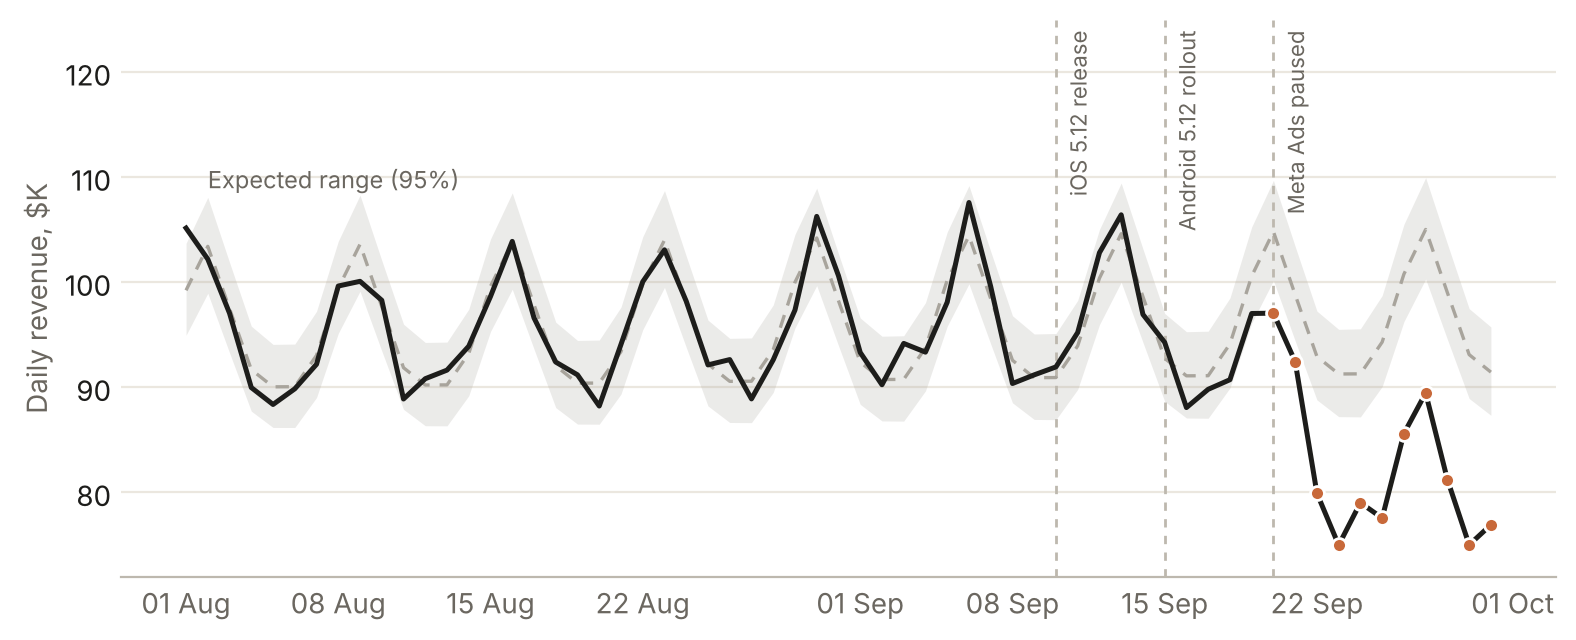

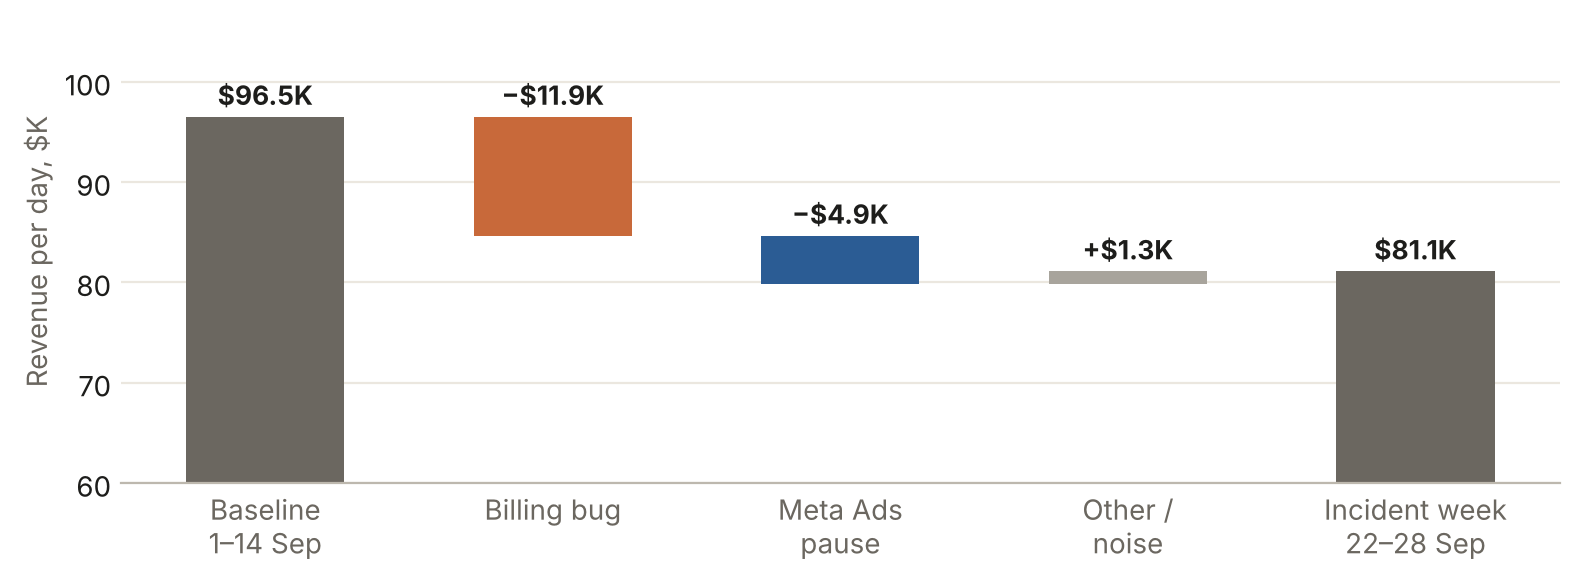

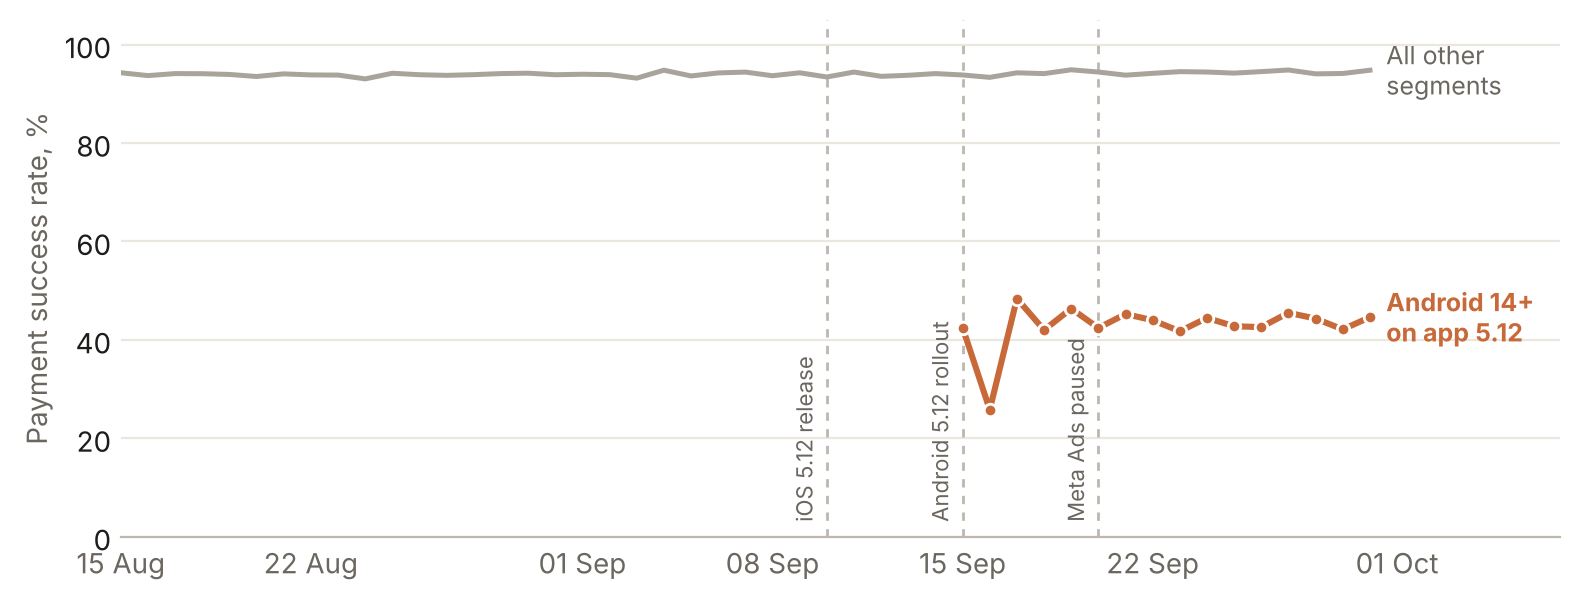

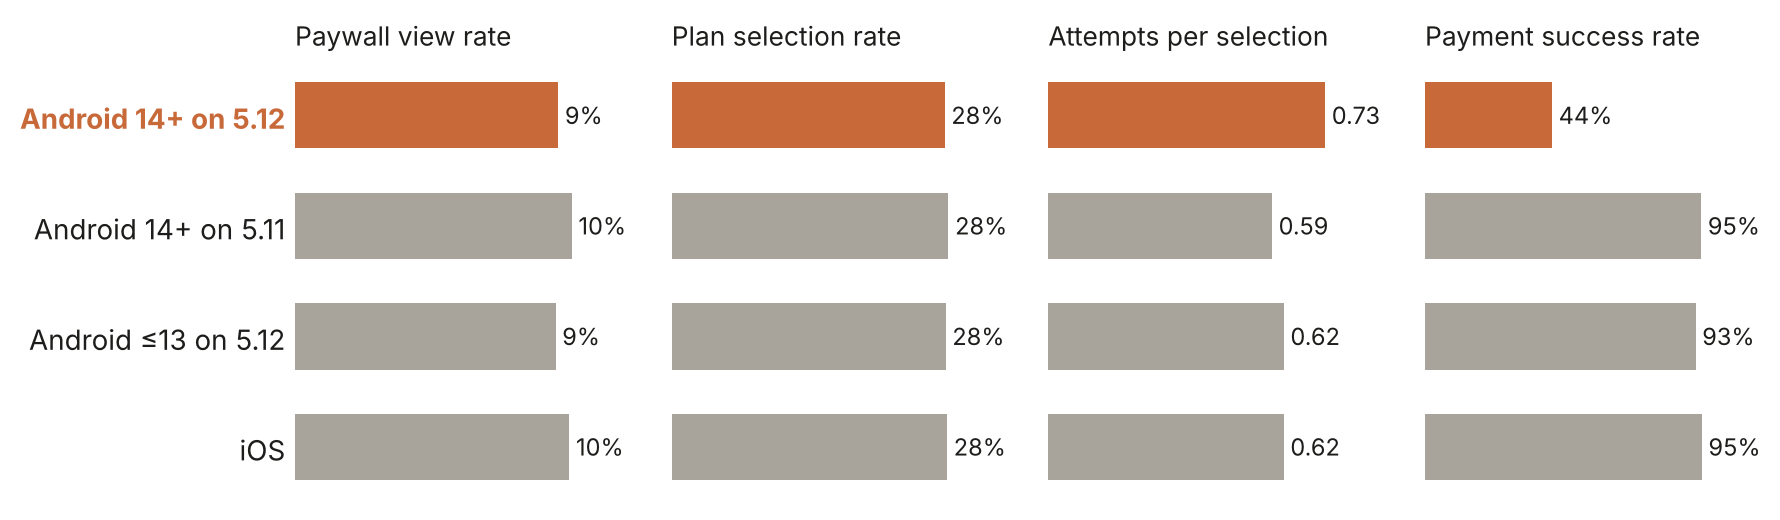

In [10]:
W, M, INK, INK2, RULE, GRID, OTHER = "#2b5c94", "#c8693a", "#1d1d1b", "#6b6760", "#bdb8ae", "#ebe7df", "#a8a49c"
plt.rcParams.update({"font.family": "Inter", "font.size": 10, "text.color": INK, "axes.spines.top": False,
    "axes.spines.right": False, "axes.spines.left": False, "axes.edgecolor": RULE, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK, "xtick.major.size": 0, "ytick.major.size": 0, "savefig.transparent": True})
import matplotlib.dates as mdates

def events(ax, ytop, va="top", left=False):
    for i, (k, v) in enumerate(EV.items()):
        ax.axvline(v, color=RULE, lw=1, ls=(0, (3, 3)), zorder=1)
        x = v - pd.Timedelta(hours=8) if left else v + pd.Timedelta(hours=10)
        ax.text(x, ytop, k, fontsize=8, color=INK2, va=va, ha="right" if left else "left", rotation=90)

# E1 revenue vs expected
z = d[d.date >= "2025-08-01"]
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.fill_between(z.date, z.lo / 1000, z.hi / 1000, color=OTHER, alpha=.22, lw=0)
ax.plot(z.date, z.expected / 1000, color=OTHER, lw=1.2, ls=(0, (4, 3)))
ax.plot(z.date, z.revenue_usd / 1000, color=INK, lw=1.8)
bad = z[z.revenue_usd < z.lo]
ax.plot(bad.date, bad.revenue_usd / 1000, "o", color=M, ms=5, mec="white", mew=1, zorder=4)
events(ax, z.hi.max() / 1000 + 14); ax.set_ylim(z.revenue_usd.min() / 1000 - 3, z.hi.max() / 1000 + 15)
ax.text(pd.Timestamp("2025-08-02"), z.hi.max() / 1000 - 1, "Expected range (95%)", fontsize=8.5, color=INK2)
ax.set_ylabel("Daily revenue, $K"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.grid(axis="y", color=GRID, lw=.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig("charts/e1_anomaly.png", dpi=240)

# E2 bridge (waterfall)
fig, ax = plt.subplots(figsize=(8, 3.0))
labels = ["Baseline\n1–14 Sep", "Billing bug", "Meta Ads\npause", "Other /\nnoise", "Incident week\n22–28 Sep"]
vals = bridge.values / 1000; run = vals[0]
for i, (lab, v) in enumerate(zip(labels, vals)):
    if i in (0, 4):
        ax.bar(i, v, color=INK2, width=.55); ax.text(i, v + 1.2, f"${v:.1f}K", ha="center", fontweight="bold", fontsize=9.5)
    else:
        c = M if i == 1 else (W if i == 2 else OTHER)
        ax.bar(i, v, bottom=run, color=c, width=.55)
        sign = "−" if v < 0 else "+"
        ax.text(i, max(run, run + v) + 1.2, f"{sign}${abs(v):.1f}K", ha="center", fontsize=9.5, fontweight="bold")
        run += v
ax.set_xticks(range(5), labels); ax.set_ylim(60, vals[0] * 1.1); ax.set_ylabel("Revenue per day, $K")
ax.grid(axis="y", color=GRID, lw=.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig("charts/e2_bridge.png", dpi=240)

# E3 payment success rate
s = succ.loc["2025-08-15":]
fig, ax = plt.subplots(figsize=(8, 3.1))
ax.plot(s.index, s["all other"] * 100, color=OTHER, lw=1.8)
ax.plot(s.index, s["affected"] * 100, color=M, lw=2.2, marker="o", ms=4.5, mec="white", mew=1)
ax.text(s.index[-1] + pd.Timedelta(days=0.6), s["all other"].iloc[-1] * 100, "All other\nsegments", color=INK2, fontsize=9, va="center")
ax.text(s.index[-1] + pd.Timedelta(days=0.6), s["affected"].iloc[-1] * 100, "Android 14+\non app 5.12", color=M, fontsize=9,
        va="center", fontweight="bold")
events(ax, 3, va="bottom", left=True)
ax.set_ylim(0, 105); ax.set_xlim(s.index[0], s.index[-1] + pd.Timedelta(days=7))
ax.set_ylabel("Payment success rate, %"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.grid(axis="y", color=GRID, lw=.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig("charts/e3_success.png", dpi=240)

# E4 funnel comparison
fig, axes = plt.subplots(1, 4, figsize=(9, 2.7), sharey=True)
cols = list(fun.columns); colr = [M, OTHER, OTHER, OTHER]
for ax, step in zip(axes, fun.index):
    v = fun.loc[step]
    for j, (c, cc) in enumerate(zip(cols, colr)):
        ax.barh(j, v[c] * (100 if step != "Attempts per selection" else 1), color=cc, height=.6)
        lab = f"{v[c]*100:.0f}%" if step != "Attempts per selection" else f"{v[c]:.2f}"
        ax.text(v[c] * (100 if step != "Attempts per selection" else 1), j, " " + lab, va="center", fontsize=8.5)
    ax.set_title(step, fontsize=9.5, loc="left"); ax.set_xticks([])
    ax.spines["bottom"].set_visible(False)
axes[0].set_yticks(range(4), ["Android 14+ on 5.12", "Android 14+ on 5.11", "Android ≤13 on 5.12", "iOS"])
axes[0].invert_yaxis()
for t, c in zip(axes[0].get_yticklabels(), colr):
    t.set_color(c if c == M else INK); t.set_fontweight("bold" if c == M else "normal")
fig.tight_layout(w_pad=1.5); fig.savefig("charts/e4_funnel.png", dpi=240)
plt.show()

In [11]:
out = dict(onset=str(onset.date()), r2=m.rsquared, dec=dec.to_dict(), share=share,
           platform=drill("platform").to_dict("index"), cells=cells.to_dict("records"), funnel=fun.to_dict(),
           natural=ne.to_dict("index"), total_loss=total_loss, run_rate=run_rate,
           run_rate_share=run_rate / day.loc["2025-09-24":"2025-09-30"].revenue_usd.mean(),
           meta_effect=meta_effect, bug_week=bug_week, bridge=bridge.to_dict(),
           meta_inst=[mi.loc["2025-09-01":"2025-09-14"].mean(), mi.loc["2025-09-22":"2025-09-28"].mean()],
           gap_last7=d[d.date >= "2025-09-24"].gap.mean())
json.dump(out, open("results.json", "w"), default=float, indent=1)